In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append('../')


from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import torch

from utils.custom_loader import custom_loader_training
from utils.mm_classifier import mm_classifier
from utils.custom_a_handles import custom_normalize, custom_to_tensor, custom_gauss_noise, custom_normalize99

#using albumentations library
import albumentations as A
#import albumentations.augmentations.functional as F
from albumentations.pytorch import ToTensorV2

# from utils.unet import UNet
from utils.unet import UNet, UNet_deep

from skimage import io
import cv2
import matplotlib.pyplot as plt
import numpy as np

from utils.load_files import getTrainingPairs

from sklearn.model_selection import train_test_split
import time, datetime

from utils.cell_aware_crop import CellAwareCrop

from main import train_net
from imageio.v3 import imwrite


In [3]:
# Set training parameters for cell segmentation
train_dirs =[
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9767/KI_data','', 1.0),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/KI_data_2','', 1.0, 0),  # 4th value: validation fraction (default 0.2), 0 = training only
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/EXP-26-CF5403/train', '', 300/500),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/EXP-26-CF5404/train', '', 300/600),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/EXP-26-CE7551/train', '', 300/500),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/EXP-26-CE7556/train', '', 300/500),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/EXP-26-CE8758/train', '', 300/400),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9774/EXP-26-CE8770_A/train', '', 300/400),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9774/EXP-26-CE8770_B/train', '', 300/400),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9774/EXP-26-CE8772/train', '', 300/400),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9774/EXP-26-CE8775/train', '', 300/400),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9774/EXP-26-CE8778_A/train', '', 300/400),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9774/EXP-26-CE8778_B/train', '', 300/400),
                ]
save_dir = '/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769'
net_size = 512
batch_size = 6
crop_window = 352#256
normalize = custom_normalize99
num_epochs = 120


training_transform = A.Compose(
    [
        # 1. intensity, on the real image only
        A.RandomBrightnessContrast(p=0.3),
        A.RandomGamma(gamma_limit=(70, 200), p=0.5),
        A.Illumination(p=0.3),
        A.GaussianBlur(p=0.6, blur_limit=0, sigma_limit=(0.1, 1.0)),
        A.Downscale(scale_range=(0.5, 0.9), p=0.2),
        A.Lambda(name='normalize', image=normalize, p=1.0),
        A.GaussNoise(std_range=(2/255, 20/255), mean_range=(0, 0), p=0.5),
        A.MultiplicativeNoise(multiplier=(0.9, 1.1), elementwise=True, p=0.5),
        # 2. geometry, borders filled by reflecting real content
        A.Affine(p=0.8, scale=(0.85, 1.15), rotate=(-5, 5), border_mode=cv2.BORDER_REFLECT),
        # 3. pad with clean zeros (as at inference), then crop
        A.PadIfNeeded(min_height=crop_window, min_width=crop_window, border_mode=cv2.BORDER_CONSTANT, fill=0, fill_mask=0, p=1),
        A.RandomCrop(crop_window, crop_window, p=1),
        A.SquareSymmetry(p=1),
        A.Lambda(name='to_tensor', image=custom_to_tensor, mask=custom_to_tensor, p=1.0),
    ]
)

Image mean: 0.0955, std: 0.1491, min: 0.0000, max: 0.9986


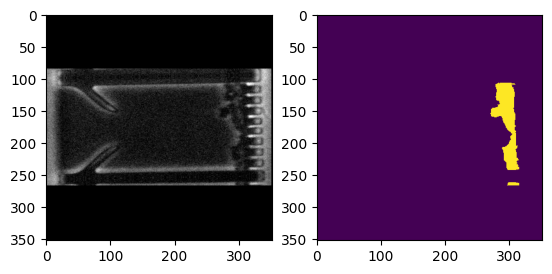

In [9]:
# Test the dataset and transformations
phase, mask, scales = [], [], []
for d, nm, s, *_ in train_dirs:
    p, m = getTrainingPairs([(d, nm)])
    phase += p
    mask += m
    scales += [s] * len(p)
training_dataset = custom_loader_training(phase_ims = phase,
                                          mask_ims  = mask,
                                          scales = scales,
                                          transform = training_transform)

im, m = training_dataset[0]
fig,axs = plt.subplots(1,2)
axs[0].imshow(im.squeeze(),cmap='gray')
axs[1].imshow(m.squeeze())
print(f"Image mean: {im.mean():.4f}, std: {im.std():.4f}, min: {im.min():.4f}, max: {im.max():.4f}")

/home/spartak/elflab/BSL3/analysis/EXP-26-CB9767/KI_data: 809 train, 203 validation
/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/KI_data_2: 3 train, 0 validation
/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/EXP-26-CF5403/train: 100 train, 26 validation
/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/EXP-26-CF5404/train: 139 train, 35 validation
/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/EXP-26-CE7551/train: 35 train, 9 validation
/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/EXP-26-CE7556/train: 37 train, 10 validation
/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/EXP-26-CE8758/train: 137 train, 35 validation
/home/spartak/elflab/BSL3/analysis/EXP-26-CB9774/EXP-26-CE8770_A/train: 186 train, 47 validation
/home/spartak/elflab/BSL3/analysis/EXP-26-CB9774/EXP-26-CE8770_B/train: 87 train, 22 validation
/home/spartak/elflab/BSL3/analysis/EXP-26-CB9774/EXP-26-CE8772/train: 44 train, 12 validation
/home/spartak/elflab/BSL3/analysis/EXP-26-CB9774/EXP-26-CE8775/train: 72 tr

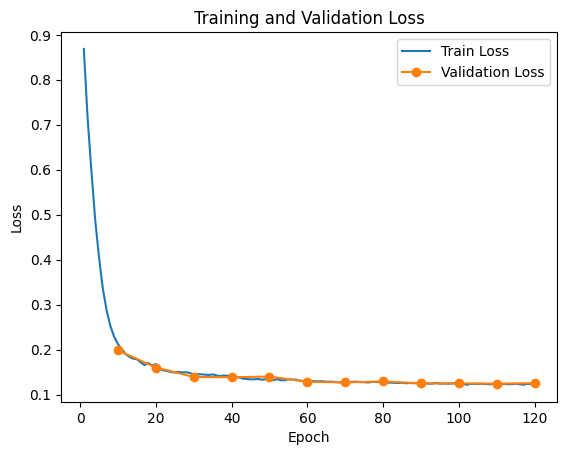

In [10]:
# Run training
train_net(train_dirs,save_dir, net_size=512, training_transform=training_transform, num_epochs=num_epochs,
          batch_size=batch_size, normalize=normalize, val_fraction=0.2, seed=0)

/home/spartak/elflab/BSL3/analysis/EXP-26-CB9767/KI_data: 809 train, 203 validation
/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/KI_data_2: 2 train, 1 validation
/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/EXP-26-CF5403/train: 100 train, 26 validation
/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/EXP-26-CF5404/train: 139 train, 35 validation
/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/EXP-26-CE7551/train: 35 train, 9 validation
/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/EXP-26-CE7556/train: 37 train, 10 validation
/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/EXP-26-CE8758/train: 137 train, 35 validation
/home/spartak/elflab/BSL3/analysis/EXP-26-CB9774/EXP-26-CE8770_A/train: 186 train, 47 validation
/home/spartak/elflab/BSL3/analysis/EXP-26-CB9774/EXP-26-CE8770_B/train: 87 train, 22 validation
/home/spartak/elflab/BSL3/analysis/EXP-26-CB9774/EXP-26-CE8772/train: 44 train, 12 validation
/home/spartak/elflab/BSL3/analysis/EXP-26-CB9774/EXP-26-CE8775/train: 72 tr

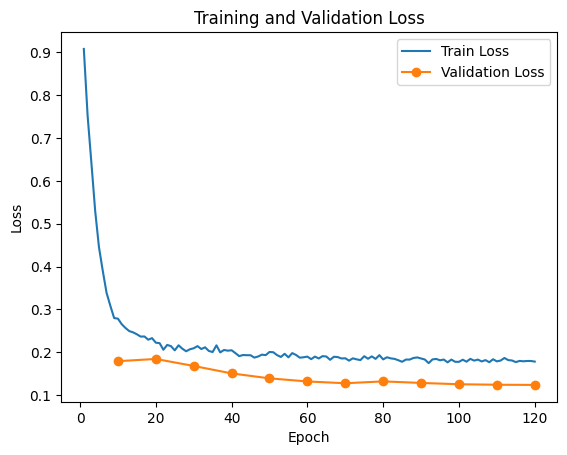

In [ ]:
# Train a model without image rescaling for comparison
train_dirs =[
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9767/KI_data','', 1.0),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/KI_data_2','', 1.0, 0),  # 4th value: validation fraction (default 0.2), 0 = training only
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/EXP-26-CF5403/train', '', 1.0),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/EXP-26-CF5404/train', '', 1.0),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/EXP-26-CE7551/train', '', 1.0),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/EXP-26-CE7556/train', '', 1.0),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/EXP-26-CE8758/train', '', 1.0),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9774/EXP-26-CE8770_A/train', '', 1.0),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9774/EXP-26-CE8770_B/train', '', 1.0),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9774/EXP-26-CE8772/train', '', 1.0),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9774/EXP-26-CE8775/train', '', 1.0),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9774/EXP-26-CE8778_A/train', '', 1.0),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9774/EXP-26-CE8778_B/train', '', 1.0),
                ]

train_net(train_dirs,save_dir, net_size=512, training_transform=training_transform, num_epochs=num_epochs,
          batch_size=batch_size, normalize=normalize, val_fraction=0, seed=0)

In [18]:
# Compare models with and without rescaling on the validation images, at the original image resolution
import json
import pandas as pd

def predict_full(img, net, scale=1.0, normalize=custom_normalize99):
    """Rescale image, zero-pad to a multiple of 16, predict, and return probabilities at the original size."""
    h, w = img.shape
    if scale != 1.0:
        img = cv2.resize(img, (round(w * scale), round(h * scale)), interpolation=cv2.INTER_AREA)
    sh, sw = img.shape
    img = np.pad(img, ((0, -sh % 16), (0, -sw % 16)), mode='constant')
    x = torch.from_numpy(normalize(img)).float()[None, None].cuda()
    prob = torch.sigmoid(net(x)).cpu().numpy()[0, 0, :sh, :sw]
    if scale != 1.0:
        prob = cv2.resize(prob, (w, h), interpolation=cv2.INTER_LINEAR)
    return prob

def evaluate_models(models, split_json, train_dirs, net_size=512, normalize=custom_normalize99, threshold=0.5):
    """
    models: {name: (checkpoint_path, use_rescaling)}. Scale factors are taken from train_dirs;
    use_rescaling=False runs the model on the original images.
    Returns one row per dataset and model, plus an 'all' row per model.
    Masks are binary with touching cells, so metrics are pixel-based (no per-cell matching).
    """
    val_files = set(json.load(open(split_json))['validation'])
    #pair each validation image with its mask, dataset and scale factor
    items = []
    for d, nm, s, *_ in train_dirs:
        for p, m in zip(*getTrainingPairs([(d, nm)])):
            if p in val_files:
                items.append((p, m, d.replace('/train', '').split('/')[-1], s))

    rows = []
    for name, (path, use_rescaling) in models.items():
        net = UNet(max_filters=net_size)
        net.load_state_dict(torch.load(path)['model_state_dict'])
        net.cuda().eval()
        per_image = []
        with torch.no_grad():
            for p, m, dataset, s in items:
                img = io.imread(p, as_gray=True)
                gt = io.imread(m, as_gray=True) > 0
                pred = predict_full(img, net, s if use_rescaling else 1.0, normalize) > threshold
                per_image.append(dict(dataset=dataset, inter=(pred & gt).sum(), pred_px=pred.sum(), gt_px=gt.sum()))
        df = pd.DataFrame(per_image)
        for dataset, g in list(df.groupby('dataset', sort=False)) + [('all', df)]:
            tot = g.sum(numeric_only=True)
            rows.append(dict(model=name, dataset=dataset, n_images=len(g),
                             dice=2 * tot.inter / (tot.pred_px + tot.gt_px),
                             iou=tot.inter / (tot.pred_px + tot.gt_px - tot.inter),
                             precision=tot.inter / tot.pred_px,
                             recall=tot.inter / tot.gt_px))
        del net
        torch.cuda.empty_cache()
    return pd.DataFrame(rows)

train_dirs =[
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9767/KI_data','', 1.0),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/KI_data_2','', 1.0, 0),  # 4th value: validation fraction (default 0.2), 0 = training only
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/EXP-26-CF5403/train', '', 300/500),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/EXP-26-CF5404/train', '', 300/600),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/EXP-26-CE7551/train', '', 300/500),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/EXP-26-CE7556/train', '', 300/500),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/EXP-26-CE8758/train', '', 300/400),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9774/EXP-26-CE8770_A/train', '', 300/400),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9774/EXP-26-CE8770_B/train', '', 300/400),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9774/EXP-26-CE8772/train', '', 300/400),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9774/EXP-26-CE8775/train', '', 300/400),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9774/EXP-26-CE8778_A/train', '', 300/400),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9774/EXP-26-CE8778_B/train', '', 300/400),
                ]

# Fill in the _best.pth checkpoints and the split file written during training (both runs use the same split)
models = {
    'rescaled':   ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/models/unetTB_512_261015_171331_best.pth', True),
    'no rescale': ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/models/unetTB_512_261015_180930_best.pth', False),
}
split_json = '/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/models/unetTB_512_261015_171331_split.json'

results = evaluate_models(models, split_json, train_dirs, net_size=512, normalize=normalize)
results.to_csv(split_json.replace('_split.json', '_comparison.csv'), index=False)
# pixels pooled per dataset; precision < recall means too much is segmented as cell, precision > recall means too little
results.pivot(index='dataset', columns='model', values=['dice', 'precision', 'recall']).round(3)

dice           precision              recall         
model           no rescale rescaled no rescale rescaled no rescale rescaled
dataset                                                                    
EXP-26-CE7551        0.962    0.966      0.955    0.951      0.968    0.981
EXP-26-CE7556        0.946    0.955      0.979    0.973      0.916    0.937
EXP-26-CE8758        0.938    0.940      0.933    0.926      0.943    0.954
EXP-26-CE8770_A      0.907    0.909      0.919    0.908      0.895    0.909
EXP-26-CE8770_B      0.897    0.897      0.878    0.880      0.916    0.914
EXP-26-CE8772        0.918    0.922      0.910    0.913      0.926    0.932
EXP-26-CE8775        0.967    0.966      0.970    0.966      0.965    0.967
EXP-26-CE8778_A      0.892    0.887      0.900    0.903      0.884    0.872
EXP-26-CE8778_B      0.926    0.926      0.923    0.925      0.929    0.926
EXP-26-CF5403        0.920    0.925      0.913    0.904      0.928    0.946
EXP-26-CF5404        0.883    0.898      0.878    0.886      0.889    0.911
KI_data              0.949    0.953      0.941    0.949      0.957    0.956
all                  0.914    0.915      0.916    0.917      0.913    0.914

/home/spartak/elflab/BSL3/analysis/EXP-26-CB9767/KI_data: 1012 train, 0 validation
/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/KI_data_2: 3 train, 0 validation
/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/EXP-26-CF5403/train: 126 train, 0 validation
/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/EXP-26-CF5404/train: 174 train, 0 validation
/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/EXP-26-CE7551/train: 44 train, 0 validation
/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/EXP-26-CE7556/train: 47 train, 0 validation
/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/EXP-26-CE8758/train: 172 train, 0 validation
/home/spartak/elflab/BSL3/analysis/EXP-26-CB9774/EXP-26-CE8770_A/train: 233 train, 0 validation
/home/spartak/elflab/BSL3/analysis/EXP-26-CB9774/EXP-26-CE8770_B/train: 109 train, 0 validation
/home/spartak/elflab/BSL3/analysis/EXP-26-CB9774/EXP-26-CE8772/train: 56 train, 0 validation
/home/spartak/elflab/BSL3/analysis/EXP-26-CB9774/EXP-26-CE8775/train: 90 train, 0 

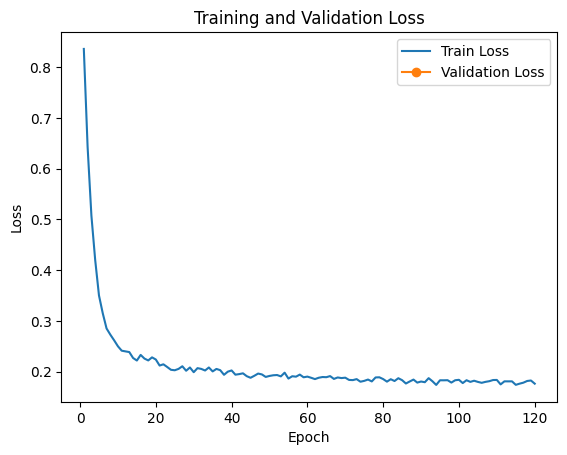

In [19]:
# Train a final model without image rescaling using all annotated images
train_dirs =[
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9767/KI_data','', 1.0),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/KI_data_2','', 1.0),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/EXP-26-CF5403/train', '', 1.0),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/EXP-26-CF5404/train', '', 1.0),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/EXP-26-CE7551/train', '', 1.0),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/EXP-26-CE7556/train', '', 1.0),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/EXP-26-CE8758/train', '', 1.0),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9774/EXP-26-CE8770_A/train', '', 1.0),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9774/EXP-26-CE8770_B/train', '', 1.0),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9774/EXP-26-CE8772/train', '', 1.0),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9774/EXP-26-CE8775/train', '', 1.0),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9774/EXP-26-CE8778_A/train', '', 1.0),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9774/EXP-26-CE8778_B/train', '', 1.0),
                ]

train_net(train_dirs,save_dir, net_size=512, training_transform=training_transform, num_epochs=num_epochs,
          batch_size=batch_size, normalize=normalize, val_fraction=0, seed=0)